# SkinCon (Fitzpatrick17k subset): download and data overview

Downloads the 3,230 usable SkinCon images, aligns them with Fitzpatrick17k labels, and summarizes the class and concept distributions.

In [ ]:
# !pip install pandas requests pillow tqdm matplotlib

## 1. Config

In [1]:
SKINCON_CSV = "image.csv"
F17K_CSV = "fitzpatrick17k.csv"
OUT_DIR = "data/skincon"
WORKERS = 16

## 2. Imports and helpers

In [2]:
import os
from concurrent.futures import ThreadPoolExecutor, as_completed

import matplotlib.pyplot as plt
import pandas as pd
import requests
from PIL import Image
from requests.adapters import HTTPAdapter
from tqdm.auto import tqdm
from urllib3.util.retry import Retry

HEADERS = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                         "(KHTML, like Gecko) Chrome/124.0 Safari/537.36"}


def make_session():
    s = requests.Session()
    retry = Retry(total=4, backoff_factor=1.0, status_forcelist=[429, 500, 502, 503, 504])
    s.mount("http://", HTTPAdapter(max_retries=retry, pool_maxsize=32))
    s.mount("https://", HTTPAdapter(max_retries=retry, pool_maxsize=32))
    s.headers.update(HEADERS)
    return s


def is_valid_image(path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False


def download_one(session, md5, url, img_dir):
    path = os.path.join(img_dir, f"{md5}.jpg")
    if os.path.exists(path) and is_valid_image(path):
        return md5, None  # already downloaded, supports resume
    if not isinstance(url, str) or not url.startswith("http"):
        return md5, "missing url"
    try:
        r = session.get(url, timeout=30)
        r.raise_for_status()
        tmp = path + ".part"
        with open(tmp, "wb") as f:
            f.write(r.content)
        if not is_valid_image(tmp):
            os.remove(tmp)
            return md5, "not a valid image"
        with Image.open(tmp) as im:  # normalize to RGB JPEG
            im.convert("RGB").save(path, "JPEG", quality=95)
        os.remove(tmp)
        return md5, None
    except Exception as e:
        return md5, f"{type(e).__name__}: {e}"[:200]

c:\Users\78479\anaconda3\envs\skinkg\lib\python\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Load and align annotations

SkinCon `ImageID` without `.jpg` equals Fitzpatrick17k `md5hash`. Images flagged "Do not consider" are removed.

In [3]:
img_dir = os.path.join(OUT_DIR, "images")
os.makedirs(img_dir, exist_ok=True)

sk = pd.read_csv(SKINCON_CSV).drop(columns=["Unnamed: 0"], errors="ignore")
print("SkinCon rows:", len(sk), "| flagged do-not-consider:", int(sk["Do not consider this image"].sum()))
sk = sk[sk["Do not consider this image"] == 0].drop(columns=["Do not consider this image"])
sk["md5"] = sk["ImageID"].str.replace(".jpg", "", regex=False)
CONCEPTS = [c for c in sk.columns if c not in ("ImageID", "md5")]

f17k = pd.read_csv(F17K_CSV)
meta = sk.merge(f17k, left_on="md5", right_on="md5hash", how="inner")
print(f"Usable images: {len(meta)} | classes: {meta['label'].nunique()} | concepts: {len(CONCEPTS)}")
print("Missing URLs:", meta["url"].isna().sum())

SkinCon rows: 3690 | flagged do-not-consider: 460
Usable images: 3230 | classes: 113 | concepts: 48
Missing URLs: 7


## 4. Download images

In [5]:
session = make_session()
failed = []
with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    futs = [ex.submit(download_one, session, r.md5, r.url, img_dir) for r in meta.itertuples()]
    for fut in tqdm(as_completed(futs), total=len(futs), desc="Downloading"):
        md5, err = fut.result()
        if err:
            failed.append((md5, err))

fail_df = pd.DataFrame(failed, columns=["md5", "error"]).merge(meta[["md5", "url"]], on="md5")
fail_df.to_csv(os.path.join(OUT_DIR, "failed.csv"), index=False)
print(f"Downloaded: {len(meta) - len(fail_df)} / {len(meta)} | failed: {len(fail_df)}")
if len(fail_df):
    display(fail_df["error"].str.split(":").str[0].value_counts().head(10))

Downloading: 100%|██████████| 3230/3230 [02:03<00:00, 26.23it/s]

Downloaded: 780 / 3230 | failed: 2450


error
HTTPError      2443
missing url       7
Name: count, dtype: int64

## 5. Save clean metadata

In [6]:
ok = meta[~meta["md5"].isin(fail_df["md5"])].reset_index(drop=True)
cols = ["md5", "label", "nine_partition_label", "three_partition_label",
        "fitzpatrick_scale", "fitzpatrick_centaur"] + CONCEPTS
ok[cols].to_csv(os.path.join(OUT_DIR, "metadata.csv"), index=False)
ok[cols].head()

,md5,label,nine_partition_label,three_partition_label,fitzpatrick_scale,fitzpatrick_centaur,Vesicle,Papule,Macule,Plaque,...,Blue,Umbilicated,Poikiloderma,Salmon,Wheal,Acuminate,Burrow,Gray,Pigmented,Cyst
0,bb3d08781eb23890a9909201deed8c85,basal cell carcinoma,malignant epidermal,malignant,3,3,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,61476bff344f64f26b8a946403681ffb,folliculitis,inflammatory,non-neoplastic,2,3,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,35e5b48aad880f40625297aae247119a,squamous cell carcinoma,malignant epidermal,malignant,-1,6,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,05110062ac68aae199c0f52403cdcf68,sarcoidosis,inflammatory,non-neoplastic,3,3,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,a5aa4c6e2727e9b49bd3fd3fd27543e6,pityriasis rosea,inflammatory,non-neoplastic,4,4,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


## 6. Class distribution (long tail)

Classes: 79 | min 1, median 5, max 65
Classes with <10 images: 56


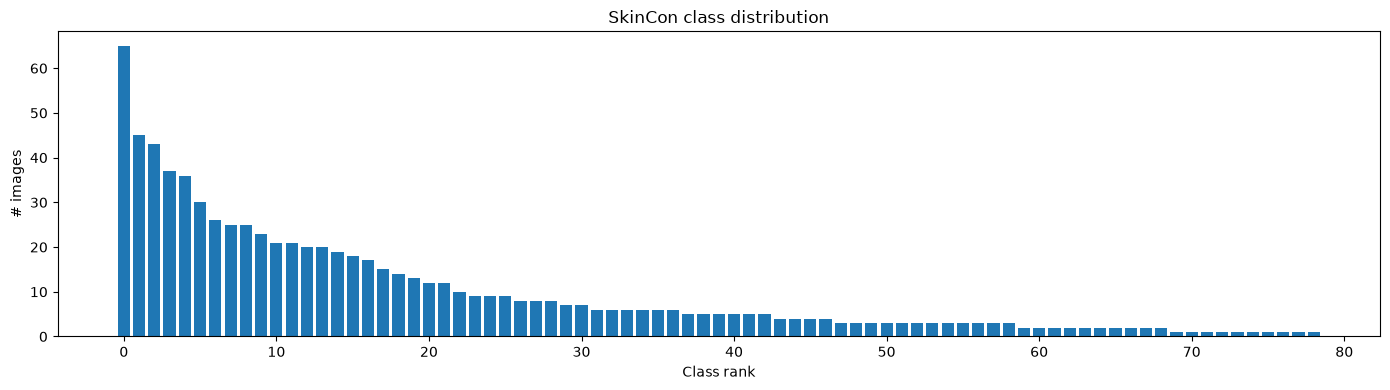

label
cheilitis                          2
factitial dermatitis               2
porphyria                          2
dermatofibroma                     2
granuloma pyogenic                 2
langerhans cell histiocytosis      1
lupus subacute                     1
eczema                             1
congenital nevus                   1
xeroderma pigmentosum              1
tick bite                          1
actinic keratosis                  1
pilomatricoma                      1
drug induced pigmentary changes    1
ichthyosis vulgaris                1
Name: count, dtype: int64

In [7]:
vc = ok["label"].value_counts()
print(f"Classes: {len(vc)} | min {vc.min()}, median {int(vc.median())}, max {vc.max()}")
print("Classes with <10 images:", (vc < 10).sum())

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(len(vc)), vc.values)
ax.set_xlabel("Class rank"); ax.set_ylabel("# images"); ax.set_title("SkinCon class distribution")
plt.tight_layout(); plt.show()

display(vc.tail(15))

## 7. Coarse categories and skin tone

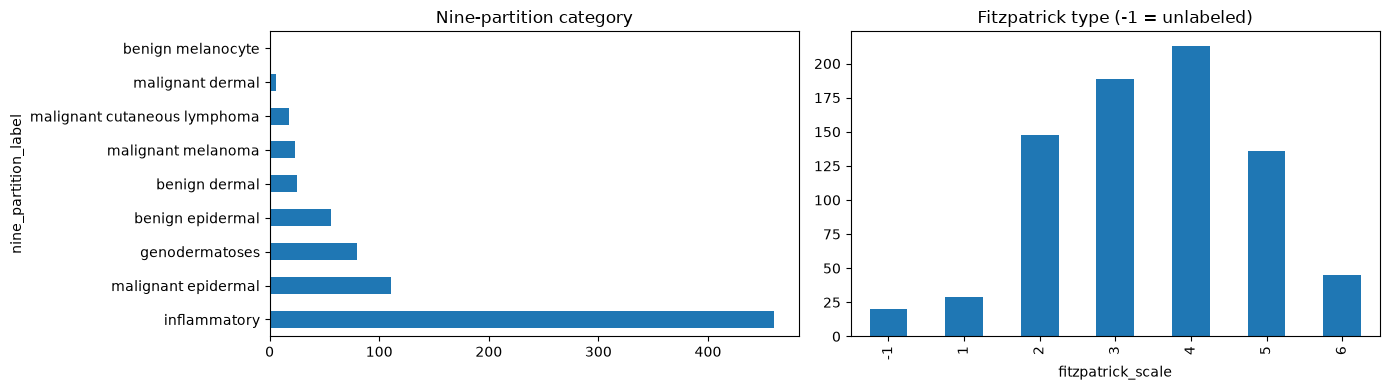

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ok["nine_partition_label"].value_counts().plot.barh(ax=axes[0], title="Nine-partition category")
ok["fitzpatrick_scale"].value_counts().sort_index().plot.bar(ax=axes[1], title="Fitzpatrick type (-1 = unlabeled)")
plt.tight_layout(); plt.show()

## 8. Concept frequency

Concepts with >= 50 images: 11


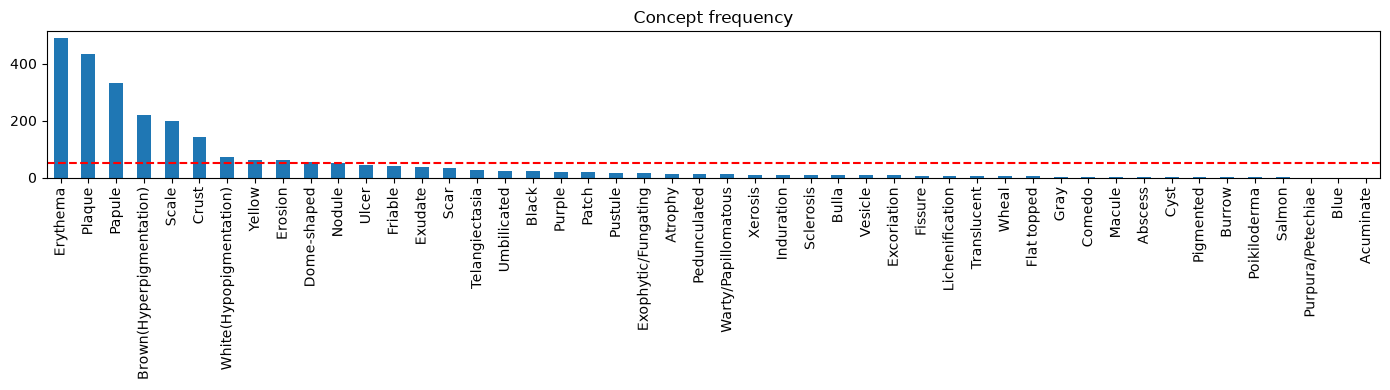

In [9]:
cc = ok[CONCEPTS].sum().sort_values(ascending=False)
print("Concepts with >= 50 images:", (cc >= 50).sum())

fig, ax = plt.subplots(figsize=(14, 4))
cc.plot.bar(ax=ax, title="Concept frequency")
ax.axhline(50, ls="--", c="r")
plt.tight_layout(); plt.show()

## 9. Visual sanity check

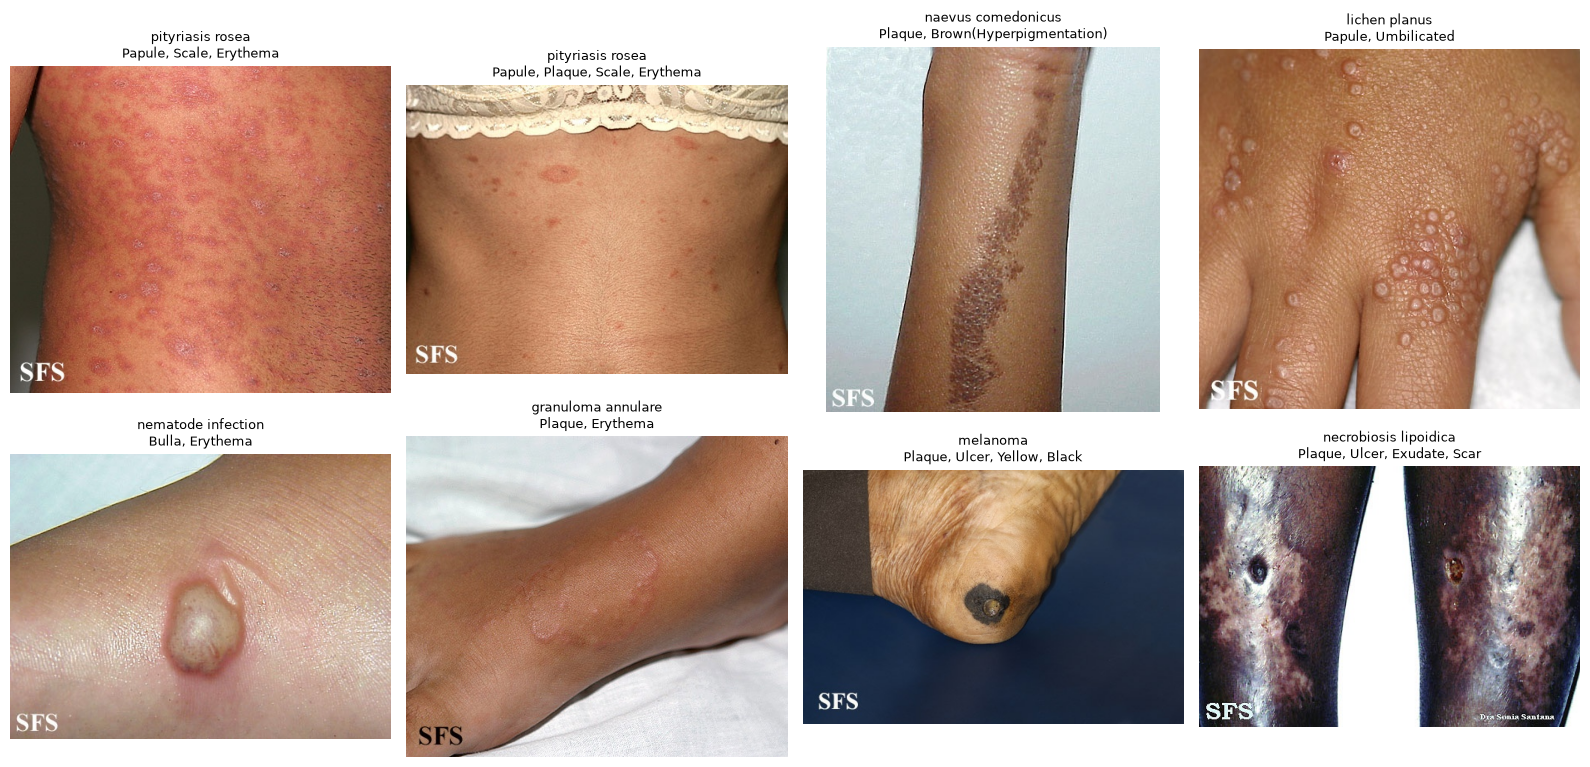

In [10]:
sample = ok.sample(8, random_state=0)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(os.path.join(img_dir, f"{r['md5']}.jpg")))
    on = [c for c in CONCEPTS if r[c] == 1]
    ax.set_title(f"{r['label']}\n{', '.join(on[:4])}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()